# EN3150 Assignment 03 — SOTA Fine-Tuning
## Fashion-MNIST transfer learning

This notebook reuses the **shared preprocessed dataset** at `data/processed/fashion_mnist_processed.npz`. It does not silently download/re-split the original dataset. If the archive uses different key names or stores a different schema, the dataset inspection cell will explain what needs adjusting.

Assignment alignment:
- Same 70% / 15% / 15% data splits as the custom CNNs.
- Maximum input resolution: **64 × 64**.
- Pretrained ImageNet backbone adapted to 10 Fashion-MNIST classes.
- Head training followed by optional partial fine-tuning.
- Test metrics, confusion matrix, parameter count, saved model size, and learning curves.

Run from the **repository root** so the relative dataset path resolves.

**Architecture:** MobileNetV2


## 1. Imports and inspect the shared processed dataset


In [12]:
from pathlib import Path
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Fix the working directory to the repository root if running from inside 'notebooks/'
if os.getcwd().endswith('notebooks'):
    os.chdir('..')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = Path("data/processed/fashion_mnist_processed.npz")
OUTPUT_DIR = Path("outputs/sota")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Run this notebook from the repository root "
        "and ensure the preprocessing commit/data file is present."
    )

archive = np.load(DATA_PATH, allow_pickle=False)
print("Archive keys:", archive.files)
for key in archive.files:
    arr = archive[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

Archive keys: ['x_train', 'y_train', 'x_val', 'y_val', 'x_test', 'y_test']
x_train: shape=(49000, 28, 28, 1), dtype=float32
y_train: shape=(49000,), dtype=uint8
x_val: shape=(10500, 28, 28, 1), dtype=float32
y_val: shape=(10500,), dtype=uint8
x_test: shape=(10500, 28, 28, 1), dtype=float32
y_test: shape=(10500,), dtype=uint8


## 2. Load the existing train/validation/test splits and prepare 64×64 inputs


In [13]:
# This loader supports common split-key naming conventions.
# If your preprocessing notebook uses different names, edit CANDIDATES below
# based on the archive keys printed in the previous cell.
CANDIDATES = {
    "x_train": ["X_train", "x_train", "train_images", "X_train_resized", "x_train_resized"],
    "y_train": ["y_train", "Y_train", "train_labels"],
    "x_val":   ["X_val", "x_val", "X_valid", "x_valid", "X_validation", "x_validation",
                "val_images", "validation_images"],
    "y_val":   ["y_val", "Y_val", "y_valid", "Y_valid", "y_validation", "Y_validation",
                "val_labels", "validation_labels"],
    "x_test":  ["X_test", "x_test", "test_images", "X_test_resized", "x_test_resized"],
    "y_test":  ["y_test", "Y_test", "test_labels"],
}

def find_key(logical_name):
    for candidate in CANDIDATES[logical_name]:
        if candidate in archive.files:
            return candidate
    return None

found = {name: find_key(name) for name in CANDIDATES}
missing = [name for name, key in found.items() if key is None]
if missing:
    raise KeyError(
        "The processed NPZ does not contain recognizable pre-split arrays for "
        f"{missing}. Available keys: {archive.files}. Do not create new splits here; "
        "update CANDIDATES to match the names used by your shared preprocessing notebook."
    )

X_train, y_train = archive[found["x_train"]], archive[found["y_train"]]
X_val, y_val = archive[found["x_val"]], archive[found["y_val"]]
X_test, y_test = archive[found["x_test"]], archive[found["y_test"]]

# Flatten labels if saved as (N, 1), and convert one-hot labels to class IDs if needed.
def normalize_labels(y):
    y = np.asarray(y)
    if y.ndim > 1 and y.shape[-1] == 10:
        y = np.argmax(y, axis=-1)
    return y.reshape(-1).astype("int64")

y_train, y_val, y_test = map(normalize_labels, (y_train, y_val, y_test))

assert len(X_train) == len(y_train) and len(X_val) == len(y_val) and len(X_test) == len(y_test)
assert set(np.unique(y_train)).issubset(set(range(10))), "Expected class IDs 0–9."
print("Loaded shared splits:", len(X_train), "train;", len(X_val), "validation;", len(X_test), "test")
print("Split proportions:", [round(n/(len(X_train)+len(X_val)+len(X_test)), 4)
                             for n in (len(X_train), len(X_val), len(X_test))])

# Resize to 64x64 and ensure three channels for ImageNet backbones.
# Values remain in [0, 255]; model-specific preprocessing happens below.
def prepare_images(images):
    x = np.asarray(images)
    if x.ndim == 3:
        x = x[..., None]
    if x.ndim != 4:
        raise ValueError(f"Expected image array with 3 or 4 dimensions; got {x.shape}")
    if x.shape[-1] not in (1, 3, 4) and x.shape[1] in (1, 3, 4):
        x = np.transpose(x, (0, 2, 3, 1))  # NCHW -> NHWC
    if x.shape[-1] == 4:
        x = x[..., :3]
    if x.shape[-1] == 1:
        x = np.repeat(x, 3, axis=-1)
    x = tf.convert_to_tensor(x, dtype=tf.float32)
    # Standardize scale only, not the split. Recognize [0,1] or [0,255] inputs.
    max_value = float(tf.reduce_max(x).numpy()) if tf.size(x).numpy() else 0.0
    if max_value <= 1.0:
        x = x * 255.0
    x = tf.image.resize(x, (64, 64), antialias=True)
    return x.numpy().astype("float32")

X_train = prepare_images(X_train)
X_val = prepare_images(X_val)
X_test = prepare_images(X_test)

print("Final shapes:", X_train.shape, X_val.shape, X_test.shape)
assert X_train.shape[1:3] == (64, 64) and X_train.shape[-1] == 3


Loaded shared splits: 49000 train; 10500 validation; 10500 test
Split proportions: [0.7, 0.15, 0.15]
Final shapes: (49000, 64, 64, 3) (10500, 64, 64, 3) (10500, 64, 64, 3)


## 3. Build the pretrained model


In [14]:
MODEL_NAME = "MobileNetV2"
MODEL_STEM = "mobilenetv2"
NUM_CLASSES = 10
BATCH_SIZE = 128
HEAD_EPOCHS = 5
FINE_TUNE_EPOCHS = 5
FINE_TUNE_LAST_LAYERS = 20

# Apply the correct input preprocessing for this architecture.
PREPROCESS = tf.keras.applications.mobilenet_v2.preprocess_input
def preprocess_batch(images, labels):
    images = tf.cast(images, tf.float32)
    if PREPROCESS is not None:
        images = PREPROCESS(images)
    return images, tf.cast(labels, tf.int64)

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(min(len(images), 10000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(preprocess_batch, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# ImageNet weights provide pretrained features. The new classification head predicts 10 classes.
Backbone = tf.keras.applications.MobileNetV2
backbone = Backbone(
    include_top=False,
    weights="imagenet",
    input_shape=(64, 64, 3)
)
backbone.trainable = False

inputs = tf.keras.Input(shape=(64, 64, 3), name="image")
x = inputs
# Keep preprocessing in the tf.data pipeline so the two models can use their own conventions.
x = backbone(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = tf.keras.layers.Dropout(0.2, name="dropout")(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="class_predictions")(x)
model = tf.keras.Model(inputs, outputs, name=MODEL_NAME.replace("-", "_"))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)
model.summary()
print("Total parameters:", model.count_params())
print("Trainable parameters (frozen backbone):", sum(int(tf.size(v)) for v in model.trainable_variables))


/var/folders/gw/_nbvcg0n2252sgkvqcyhs9n00000gp/T/ipykernel_81936/2890845648.py:30: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = Backbone(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 21s 2us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_predictions (Dense)       │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameters: 2270794
Trainable parameters (frozen backbone): 12810


## 4. Train the classification head, then fine-tune selected backbone layers


In [15]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint(
        str(OUTPUT_DIR / f"{MODEL_STEM}_best.keras"),
        monitor="val_loss", save_best_only=True
    )
]

start = time.perf_counter()
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks,
    verbose=1
)
head_seconds = time.perf_counter() - start

# Fine-tune the last selected layers while keeping BatchNormalization layers frozen.
backbone.trainable = True
for layer in backbone.layers[:-FINE_TUNE_LAST_LAYERS]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)
print("Trainable parameters (fine-tuning):", sum(int(tf.size(v)) for v in model.trainable_variables))

start = time.perf_counter()
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    verbose=1
)
finetune_seconds = time.perf_counter() - start
print(f"Head training seconds: {head_seconds:.1f}")
print(f"Fine-tuning seconds: {finetune_seconds:.1f}")


Epoch 1/5


/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


383/383 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.7651 - loss: 0.6976 - val_accuracy: 0.8494 - val_loss: 0.4547 - learning_rate: 0.0010
Epoch 2/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 34s 90ms/step - accuracy: 0.8375 - loss: 0.4577 - val_accuracy: 0.8586 - val_loss: 0.4150 - learning_rate: 0.0010
Epoch 3/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 35s 92ms/step - accuracy: 0.8495 - loss: 0.4221 - val_accuracy: 0.8596 - val_loss: 0.4114 - learning_rate: 0.0010
Epoch 4/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 37s 96ms/step - accuracy: 0.8552 - loss: 0.4029 - val_accuracy: 0.8604 - val_loss: 0.4075 - learning_rate: 0.0010
Epoch 5/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 37s 96ms/step - accuracy: 0.8570 - loss: 0.3955 - val_accuracy: 0.8641 - val_loss: 0.3978 - learning_rate: 0.0010
Trainable parameters (fine-tuning): 1207690
Epoch 1/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 46s 114ms/step - accuracy: 0.8694 - loss: 0.3572 - val_accuracy: 0.8750 - val_loss: 0.3694 - learning_rate: 1.0000e-05
Epoch 2/5
383/383 ━━━━━━━━━━━━━━━━━━━━ 42s 

## 5. Evaluate, plot results, and save metrics


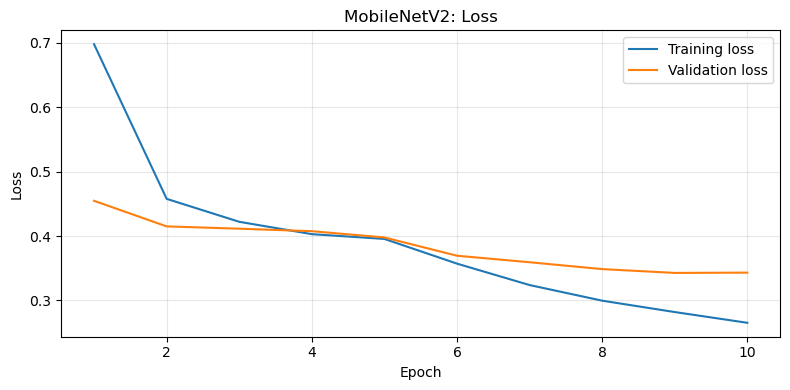

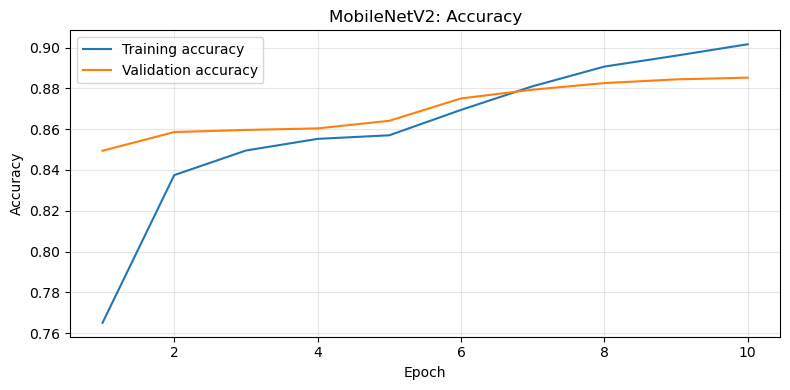

83/83 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.8823 - loss: 0.3419
83/83 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step
Test loss: 0.3419
Test accuracy: 88.2286%
Macro precision: 0.8815
Macro recall: 0.8823
\nClassification report:
              precision    recall  f1-score   support

           0     0.8458    0.8305    0.8381      1050
           1     0.9734    0.9752    0.9743      1050
           2     0.8239    0.8419    0.8328      1050
           3     0.8683    0.8667    0.8675      1050
           4     0.7905    0.8229    0.8063      1050
           5     0.9533    0.9524    0.9528      1050
           6     0.7171    0.6686    0.6920      1050
           7     0.9179    0.9371    0.9274      1050
           8     0.9671    0.9800    0.9735      1050
           9     0.9577    0.9476    0.9526      1050

    accuracy                         0.8823     10500
   macro avg     0.8815    0.8823    0.8817     10500
weighted avg     0.8815    0.8823    0.8817     10500



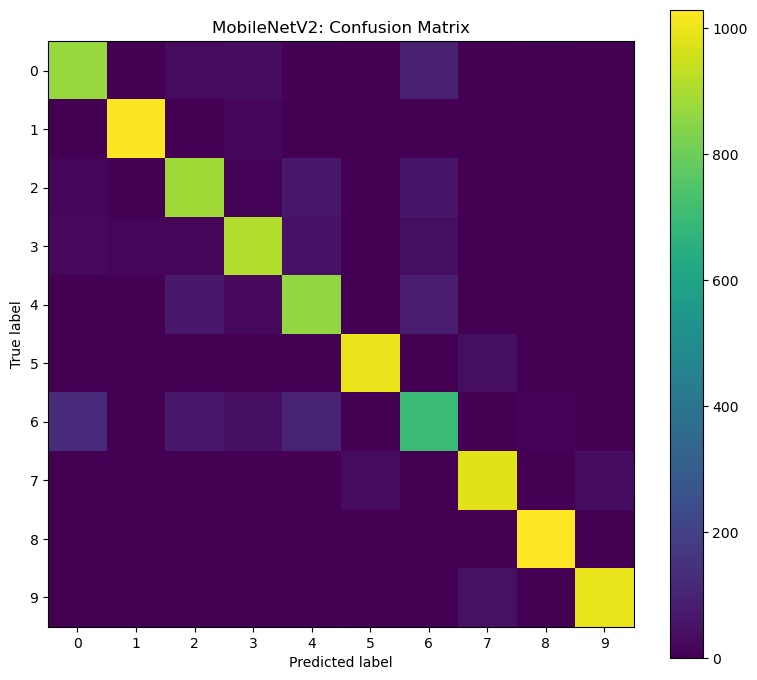

\nSaved summary:
{
  "model": "MobileNetV2",
  "input_resolution": "64x64x3",
  "dataset_path": "data/processed/fashion_mnist_processed.npz",
  "train_samples": 49000,
  "validation_samples": 10500,
  "test_samples": 10500,
  "total_parameters": 2270794,
  "trainable_parameters_after_finetuning": 1207690,
  "model_size_mb": 18.447,
  "test_loss": 0.3418627977371216,
  "test_accuracy": 0.8822857141494751,
  "macro_precision": 0.8814843049664679,
  "macro_recall": 0.8822857142857143,
  "head_training_seconds": 179.83,
  "fine_tuning_seconds": 224.04
}


In [16]:
# Combine the two training phases for plots.
def combine_histories(h1, h2):
    combined = {}
    for key in set(h1.history) | set(h2.history):
        combined[key] = h1.history.get(key, []) + h2.history.get(key, [])
    return combined

hist = combine_histories(history_head, history_finetune)
epochs = range(1, len(hist.get("loss", [])) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, hist["loss"], label="Training loss")
plt.plot(epochs, hist["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{MODEL_NAME}: Loss")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_STEM}_loss.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs, hist["accuracy"], label="Training accuracy")
plt.plot(epochs, hist["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"{MODEL_NAME}: Accuracy")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_STEM}_accuracy.png", dpi=150)
plt.show()

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = y_test

from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")
print(f"Macro precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro recall: {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print("\\nClassification report:")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

plt.figure(figsize=(8, 7))
plt.imshow(cm, interpolation="nearest")
plt.title(f"{MODEL_NAME}: Confusion Matrix")
plt.colorbar()
ticks = np.arange(10)
plt.xticks(ticks, ticks); plt.yticks(ticks, ticks)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"{MODEL_STEM}_confusion_matrix.png", dpi=150)
plt.show()

# Save final model and report its on-disk size.
final_model_path = OUTPUT_DIR / f"{MODEL_STEM}_final.keras"
model.save(final_model_path)
model_size_mb = final_model_path.stat().st_size / (1024**2)
trainable_params = sum(int(tf.size(v)) for v in model.trainable_variables)
summary = {
    "model": MODEL_NAME,
    "input_resolution": "64x64x3",
    "dataset_path": str(DATA_PATH),
    "train_samples": int(len(X_train)),
    "validation_samples": int(len(X_val)),
    "test_samples": int(len(X_test)),
    "total_parameters": int(model.count_params()),
    "trainable_parameters_after_finetuning": int(trainable_params),
    "model_size_mb": round(model_size_mb, 3),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
    "head_training_seconds": round(head_seconds, 2),
    "fine_tuning_seconds": round(finetune_seconds, 2)
}
summary_path = OUTPUT_DIR / f"{MODEL_STEM}_metrics.json"
summary_path.write_text(json.dumps(summary, indent=2))
print("\\nSaved summary:")
print(json.dumps(summary, indent=2))


## Notes before running

1. Run all cells from the repository root, where `data/processed/fashion_mnist_processed.npz` exists.
2. The archive must contain already separated train, validation and test arrays. If key names differ, edit `CANDIDATES` in the loader cell; do not make a new split in this notebook.
3. If your preprocessed NPZ uses a different path or schema, update the path/key mapping to match the actual preprocessing notebook.
4. The notebook saves metrics, plots and models under `outputs/sota/`.
5. First run downloads ImageNet weights if they are not cached. Internet access may be needed once.
6. Results will differ by hardware, TensorFlow version, random seeds and training duration. Do not write results into the report until this notebook has actually run successfully.
